# 05 — Confusion Matrices: *which particles* do we classify well?

**Prerequisites:** notebooks 00–04. Runtime ~6 min (mostly data loading + one quantum training).

Notebooks 03–04 reported everything as ROC AUC — one number per model, threshold-free. This
notebook asks the question AUC deliberately averages away: **when the model makes a decision,
which particles does it get right, and which does it confuse?**

Two tools, built on the same trained models:

1. the classic **2×2 confusion matrix** (true class × predicted class) — which introduces the one
   thing AUC let us avoid: a **decision threshold**;
2. a **species-resolved matrix** (true *particle* × predicted class) — possible because the patch
   file stores the PDG code of every patch's labelling particle. This is the "how well do we
   classify different particle types" question, answered without any new training task.

And one deliberately *negative* demonstration at the end: why a full species-vs-species
classifier (μ vs π vs p vs e vs γ) is the wrong task at pixel level — which is precisely why
Phase B switches to particle-level images for species ID.

## 1. What a confusion matrix is, and the threshold it forces

A model outputs a continuous score. AUC evaluates the *ranking* of all scores and never asks for
a decision. A confusion matrix is what you get after you **commit**: every patch with score above
some threshold is *called* shower, the rest *called* track, and the matrix counts the four
outcomes:

|  | called track | called shower |
|---|---|---|
| **truly track** | correct | mistake (track → shower) |
| **truly shower** | mistake (shower → track) | correct |

The threshold is a *choice*: raise it and you call fewer patches shower (purer shower sample,
less complete). We use 0.5 — defensible here because the classes are near-balanced — but
remember every number below moves with it; the AUC numbers of notebook 04 do not.

In [1]:
import sys, pathlib, time
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from qmllar import configs
from qmllar.preprocess import normalise
from qmllar.torch_quanv import QuanvLayer

dev = "cuda" if torch.cuda.is_available() else "cpu"

# --- data: identical subsets to notebook 04 (same seeds), so results are comparable ---
d = np.load(ROOT / "data" / "patches_31.npz")
X = normalise(d["patches"][:, 5:26, 5:26], "log1p")
y, sp, pid = d["cls"].astype(np.int64), d["split"], d["pid"]

rng_eval = np.random.default_rng(2024)                       # same as notebook 04
val_idx  = rng_eval.choice(np.flatnonzero(sp == 1),  4_000, replace=False)
test_idx = rng_eval.choice(np.flatnonzero(sp == 2), 20_000, replace=False)
tr_idx   = np.random.default_rng(1_000_000 + 10_000).choice(
               np.flatnonzero(sp == 0), 10_000, replace=False)   # 04's n=10k subset

def to_t(idx): return (torch.as_tensor(X[idx]).unsqueeze(1).to(dev),
                       torch.as_tensor(y[idx]).to(dev))
Xtr, ytr = to_t(tr_idx); Xva, yva = to_t(val_idx); Xte, yte = to_t(test_idx)
pid_te = np.abs(pid[test_idx])        # true particle species of each test patch (PDG code)
y_te   = y[test_idx]

print(f"train 10,000  val 4,000  test 20,000")
print("test species counts:", {int(k): int(v) for k, v in
      zip(*np.unique(pid_te, return_counts=True))})

train 10,000  val 4,000  test 20,000
test species counts: {11: 4020, 13: 6241, 22: 7254, 211: 789, 321: 21, 2212: 1675}


### ✅ What you should see

The test set's species census (PDG codes): **11** = e±, **22** = γ, **13** = μ±, **211** = π±,
**2212** = p, **321** = K± — photons and electrons dominating (shower pixels are many), kaons
rare. Keep these counts in mind: a species with 200 test patches gets a much noisier row than one
with 8,000.

## 2. Retrain the two reference models (same protocol as 04)

In [2]:
# Trimmed copy of 04's training engine -- fixed 2,500 steps, val checkpointing.
def head(n_ch): return nn.Sequential(nn.AvgPool2d(4), nn.Flatten(), nn.Linear(n_ch*25, 2))

def train(model, steps=2500, bs=128, lr=3e-3, seed=0):
    model = model.to(dev)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    g = torch.Generator(device=dev).manual_seed(seed)
    best, best_state = 0., None
    model.train()
    for step in range(1, steps+1):
        b = torch.randint(0, len(Xtr), (bs,), generator=g, device=dev)
        opt.zero_grad(); loss_fn(model(Xtr[b]), ytr[b]).backward(); opt.step()
        if step % 100 == 0:
            model.eval()
            with torch.no_grad():
                s = torch.cat([model(Xva[i:i+1024]) for i in range(0, len(Xva), 1024)])
            va = roc_auc_score(yva.cpu(), torch.softmax(s,1)[:,1].cpu())
            if va > best: best, best_state = va, {k:v.clone() for k,v in model.state_dict().items()}
            model.train()
    model.load_state_dict(best_state)
    return model

def shower_prob(model):
    """P(shower) for every test patch."""
    model.eval()
    with torch.no_grad():
        s = torch.cat([model(Xte[i:i+1024]) for i in range(0, len(Xte), 1024)])
    return torch.softmax(s, 1)[:, 1].cpu().numpy()

torch.manual_seed(0)
cnn_deep = train(nn.Sequential(
    nn.Conv2d(1,16,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16,32,3,padding=1), nn.ReLU(),
    nn.AdaptiveAvgPool2d(5), nn.Flatten(),
    nn.Linear(32*25,32), nn.ReLU(), nn.Linear(32,2)))
p_deep = shower_prob(cnn_deep)

torch.manual_seed(0)
quanv = train(nn.Sequential(QuanvLayer(configs.PRD_QUANV, seed=0, trainable=True), head(3)))
p_quanv = shower_prob(quanv)

for name, p in (("cnn_deep", p_deep), ("quanv", p_quanv)):
    print(f"{name:9s} test AUC {roc_auc_score(y_te, p):.4f}   (04 reported ~0.959 / ~0.910)")

cnn_deep  test AUC 0.9599   (04 reported ~0.959 / ~0.910)
quanv     test AUC 0.9115   (04 reported ~0.959 / ~0.910)


### ✅ What you should see

AUCs within ~0.002 of notebook 04's values for the same configuration — same data subsets, same
protocol, so this is a consistency check as much as a retraining.

## 3. The 2×2 confusion matrices

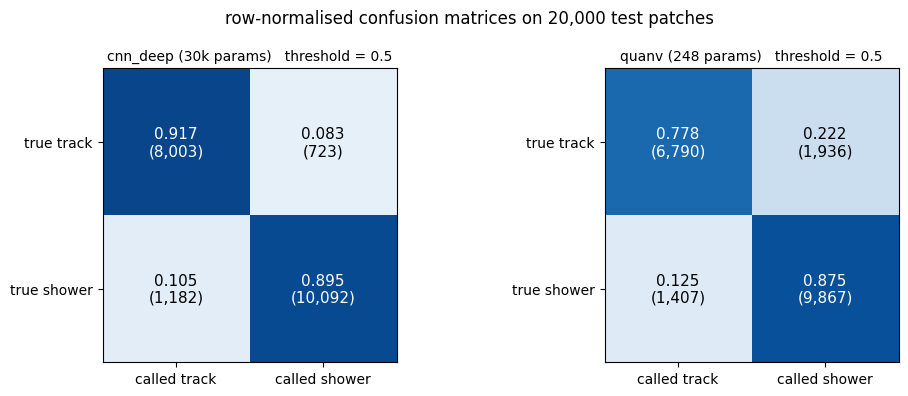

In [3]:
THRESH = 0.5
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
for ax, (name, p) in zip(axes, (("cnn_deep (30k params)", p_deep),
                                ("quanv (248 params)",   p_quanv))):
    pred = (p > THRESH).astype(int)
    # cm[i, j] = count of (true class i, predicted class j), row-normalised to rates
    cm = np.zeros((2, 2))
    for t in (0, 1):
        for q in (0, 1):
            cm[t, q] = np.mean(pred[y_te == t] == q)
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for t in (0, 1):
        for q in (0, 1):
            n = np.sum((y_te == t) & (pred == q))
            ax.text(q, t, f"{cm[t,q]:.3f}\n({n:,})", ha="center", va="center",
                    color="white" if cm[t,q] > 0.6 else "black", fontsize=11)
    ax.set_xticks([0,1], ["called track", "called shower"])
    ax.set_yticks([0,1], ["true track", "true shower"])
    ax.set_title(f"{name}   threshold = {THRESH}", fontsize=10)
fig.suptitle("row-normalised confusion matrices on 20,000 test patches")
fig.tight_layout(); plt.show()

### ✅ Reading the 2×2 matrices

| | true track called correctly | true shower called correctly |
|---|---|---|
| cnn_deep | 0.917 | 0.895 |
| quanv | **0.778** | 0.875 |

The AUC gap between these models (0.960 vs 0.911) looked like a uniform ~0.05. The matrices show
it is not: **the quantum model's errors are lopsided** — it holds its own on showers (0.875 vs
0.895) but mislabels **22% of true track pixels as shower**, double the deep CNN's rate. A single
AUC can never show *where* a model loses; this is why the matrix earns its place next to it.

Two reminders attached to every number here: they move with the 0.5 threshold (lowering it would
trade shower recall for track recall — the AUCs would not change), and they inherit notebook 04's
caveats (untuned, one seed here).

## 4. Species-resolved: *which particles* leak across the boundary

Same predictions, but now the rows are the **true particle species** (from the stored PDG code of
each patch's labelling particle). Each row answers: *of the pixels this particle produced, what
fraction did the model route to each class?* The right-hand column of each panel is that
species' correct-classification rate.

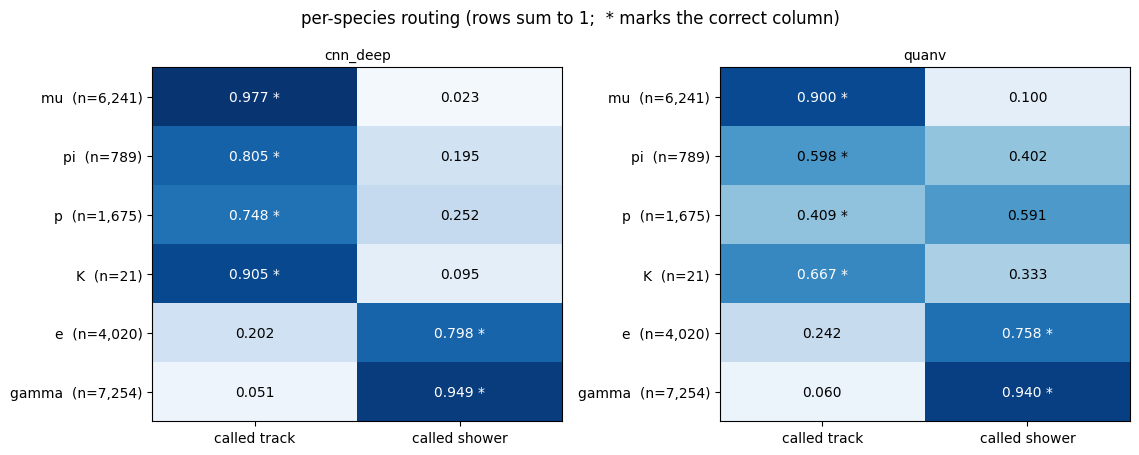

In [4]:
SPECIES = [(13, "mu",  0), (211, "pi", 0), (2212, "p", 0), (321, "K", 0),
           (11, "e", 1), (22, "gamma", 1)]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
for ax, (name, p) in zip(axes, (("cnn_deep", p_deep), ("quanv", p_quanv))):
    pred = (p > THRESH).astype(int)
    M, labels, ns = [], [], []
    for pdg, label, true_cls in SPECIES:
        m = pid_te == pdg
        if m.sum() == 0: continue
        row = [np.mean(pred[m] == 0), np.mean(pred[m] == 1)]
        M.append(row); labels.append(f"{label}  (n={m.sum():,})"); ns.append(true_cls)
    M = np.array(M)
    ax.imshow(M, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(len(M)):
        for j in (0, 1):
            correct = (j == ns[i])
            ax.text(j, i, f"{M[i,j]:.3f}" + (" *" if correct else ""),
                    ha="center", va="center",
                    color="white" if M[i,j] > 0.6 else "black", fontsize=10)
    ax.set_xticks([0,1], ["called track", "called shower"])
    ax.set_yticks(range(len(labels)), labels)
    ax.set_title(name, fontsize=10)
fig.suptitle("per-species routing (rows sum to 1;  * marks the correct column)")
fig.tight_layout(); plt.show()

### ✅ Reading the species matrix — the deficit has a name: hadrons

Correct-routing rate per species, and the deep-minus-quanv gap:

| species | cnn_deep | quanv | gap |
|---|---|---|---|
| γ (n=7,254) | 0.949 | 0.940 | 0.009 |
| μ (n=6,241) | 0.977 | 0.900 | 0.077 |
| e (n=4,020) | 0.798 | 0.758 | 0.040 |
| π (n=789) | 0.805 | 0.598 | 0.207 |
| **p (n=1,675)** | 0.748 | **0.409** | **0.339** |
| K (n=21) | — | — | too few to quote |

- **The quantum model misroutes the majority of proton pixels** (59% called shower), and 40% of
  pion pixels. On photons it is within 0.01 of the deep CNN. So the 0.05 AUC gap of notebook 04 is
  not spread evenly — **it is almost entirely a hadron problem**. Physically plausible: a proton
  is a short, dense, bright blob, locally much more like a compact EM deposit than like the long
  clean MIP line of a muon; separating it needs the subtler dE/dx information that 248 parameters
  apparently under-exploit.
- **Electrons are the hardest *shower* species for both models** (0.80 / 0.76, vs 0.95 for
  photons). A likely contributor worth checking: PDG 11 includes **delta rays** — knock-on
  electrons riding *on top of muon tracks*. Our binary scheme labels them shower, but their local
  context is a track. This is precisely why the campaign's own label scheme keeps Michel and
  DeltaRay as separate classes (§5, and inventory §3b).
- Method point for the eventual paper: **species-resolved reporting reveals structure that both
  the AUC and the 2×2 matrix hide.** If the tuned study confirms the hadron concentration, "where
  does the quantum model fail" becomes a physics statement, not just a benchmark number.

## 5. Why we do NOT train a species-vs-species classifier at pixel level

It is tempting to go one step further — a 6-class classifier, μ vs π vs p vs K vs e vs γ, and a
full 6×6 confusion matrix. At **pixel level** that task is physically degenerate, and it is worth
being precise about why:

- **μ vs π**: both are minimum-ionising tracks. The feature that separates them — the pion's
  hadronic-interaction kink, the muon's decay signature — is *metres away* from almost every pixel
  of the track. A 21×21 window (≈10 cm) cannot contain it. The 6×6 matrix would show a μ/π block
  that is essentially a coin flip, not because the model is weak but because the information is
  not in the input.
- **e vs γ**: a photon converts and then *is* an electromagnetic shower — downstream pixels are
  identical. The separating feature (the gap before conversion, dE/dx of the first segment) lives
  in a few pixels near the vertex only.
- **p vs μ/π**: the one pair that *is* partly visible locally — protons ionise more densely. The
  species-resolved matrix above already shows how much of that the binary models exploit.

This degeneracy is not a disappointment; it is the **design argument of the whole project**,
visible in data: pixel-level questions get pixel-level answers (track vs shower — Phase A), and
particle-species questions need whole-particle images with their long-range features — which is
exactly the **particle-level formulation of Phase B** on ProtoDUNE-HD, where beamline
instrumentation provides the species truth *for real data*. The plan's two task formulations
(plan §1) are not a preference — they are this physics.

Two finer tasks that *are* well-posed at pixel level, for later: the campaign's own 5-class
scheme (Track / Shower / **Michel** / **Delta ray** / **Blip** — `wc-aiml-dataset-inventory.md`
§3b) distinguishes classes by *local* appearance and ancestry, and would need only an extended
patch extraction (the mother/process information is in the campaign files); and per-species
**efficiency curves vs energy**, using the stored `ke_mev`.